# Diabetes Hospital Readmission Prediction
## Exploratory Data Analysis — Cohort v2

### 1. Introduction

This notebook explores the UCI Diabetes 130-US Hospitals dataset using the **v2 cohort**, which retains every eligible encounter after the required gender and discharge-disposition filters.

The analysis examines readmission outcomes, patient age, previous inpatient utilization, discharge disposition, encounter-level healthcare utilization, raw-data missingness, HbA1c categories, and numerical relationships.

### 2. Dataset Information

- Dataset: UCI Diabetes 130-US Hospitals Dataset
- Cohort version: v2
- Encounters: **99,340**
- Unique patients: **69,987**
- Columns: **20**
- Positive cases (`target = 1`): **11,314**
- Negative cases (`target = 0`): **88,026**
- Positive rate: **11.3892%**

**Important:** Rows represent hospital encounters, not unique patients. Patients with multiple retained encounters contribute multiple rows.

### 3. Objectives

1. Examine the 30-day readmission target distribution.
2. Study readmission rates across age groups.
3. Investigate previous inpatient utilization.
4. Examine discharge disposition categories.
5. Explore encounter-level healthcare utilization distributions.
6. Assess missingness in the original raw dataset.
7. Explore HbA1c result categories and readmission.
8. Examine correlations among numerical model attributes and the target.

### 4. Setup and Dataset Loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_PATH = Path("../data/processed/cohort_v2.parquet")
RAW_PATH = Path("../data/raw/diabetic_data.csv")
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Encounters:", len(df))
print("Unique patients:", df["patient_nbr"].nunique())
print("Positive cases:", int(df["target"].sum()))
print("Negative cases:", int((df["target"] == 0).sum()))
print("Positive rate:", f"{df['target'].mean() * 100:.4f}%")

assert df.shape == (99_340, 20)
assert df["patient_nbr"].nunique() == 69_987

display(df.head())


Dataset loaded successfully
Shape: (99340, 20)
Encounters: 99340
Unique patients: 69987
Positive cases: 11314
Negative cases: 88026
Positive rate: 11.3892%


,age,gender,race,time_in_hospital,number_inpatient,number_emergency,number_outpatient,num_lab_procedures,num_medications,number_diagnoses,admission_type_id,discharge_disposition_id,diag_1_group,A1Cresult,insulin,encounter_id,patient_nbr,target,is_first_encounter,n_stays_total
0,85,Female,Caucasian,13,0,0,0,68,28,8,2,1,Circulatory,None,Steady,12522,48330783,0,1,1
1,95,Female,Caucasian,12,0,0,0,33,18,8,3,3,Circulatory,None,Steady,15738,63555939,0,1,1
2,45,Male,Caucasian,1,0,0,0,51,8,5,1,1,Neoplasms,None,Steady,16680,42519267,0,1,1
3,45,Female,AfricanAmerican,9,0,0,0,47,17,9,1,1,Diabetes,None,Steady,28236,89869032,0,1,1
4,55,Male,Caucasian,3,0,0,0,31,16,9,2,1,Circulatory,None,Steady,35754,82637451,0,1,1


## 5. Figure 1 — Target Class Distribution

The target variable identifies whether an encounter was followed by readmission within 30 days.

- `1`: Readmitted within 30 days.
- `0`: Not readmitted within 30 days.

Because v2 retains all eligible encounters, counts and percentages in this figure describe **encounters**, not unique patients. The chart also shows the class imbalance that should be considered during model development.


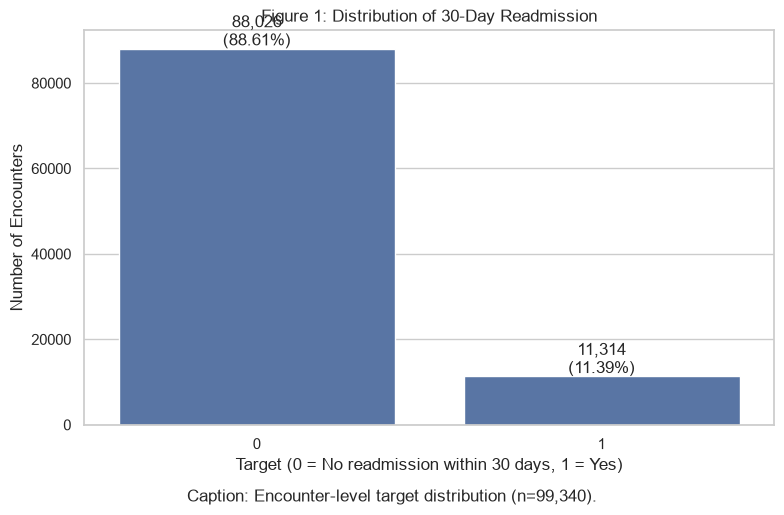

,encounters
target,
0,88026
1,11314


In [2]:
# Figure 1: Target class distribution

target_counts = df["target"].value_counts().reindex([0, 1], fill_value=0)
total = len(df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    x=target_counts.index.astype(str),
    y=target_counts.values,
    ax=ax
)

ax.set_title("Figure 1: Distribution of 30-Day Readmission")
ax.set_xlabel("Target (0 = No readmission within 30 days, 1 = Yes)")
ax.set_ylabel("Number of Encounters")

for i, count in enumerate(target_counts.values):
    ax.text(
        i, count + total * 0.008,
        f"{count:,}\n({count / total * 100:.2f}%)",
        ha="center"
    )

fig.text(
    0.5, -0.02,
    f"Caption: Encounter-level target distribution (n={total:,}).",
    ha="center"
)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig01_target_balance.png", dpi=300, bbox_inches="tight")
plt.show()

display(target_counts.rename("encounters").to_frame())


## 6. Figure 2 — Age vs Readmission Rate

The original age intervals were converted into numeric midpoints during cohort construction. This figure compares the encounter-level 30-day readmission rate across those age midpoints.

The rate for each age group is the number of positive encounters divided by all encounters in that age group. The sample size is displayed to provide context for each estimate.


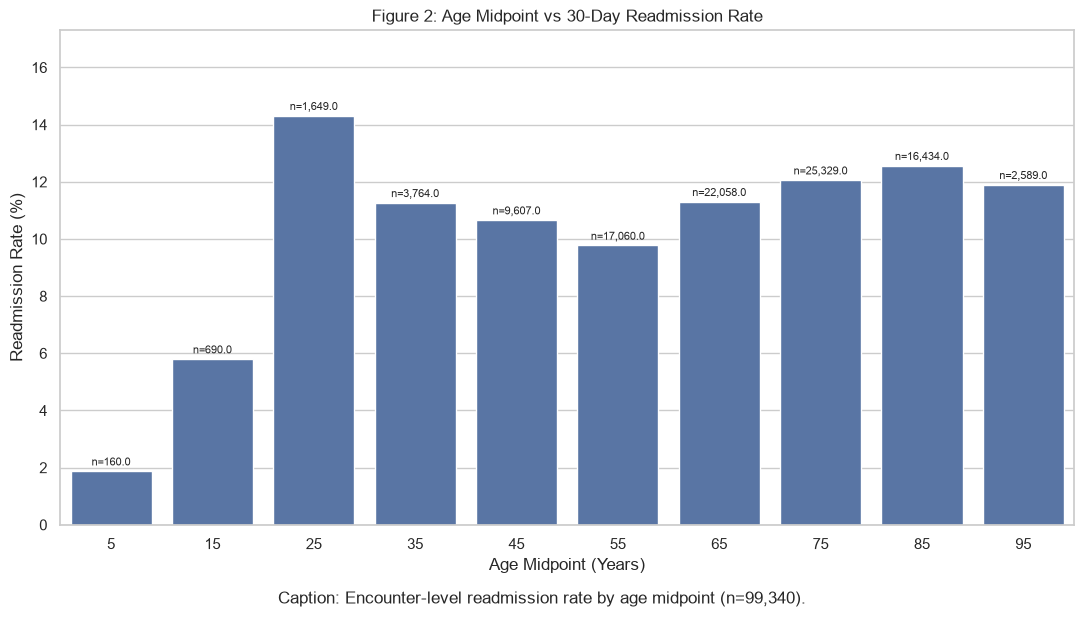

,age,total_encounters,readmitted,readmission_rate
0,5,160,3,1.875000
1,15,690,40,5.797101
2,25,1649,236,14.311704
3,35,3764,424,11.264612
4,45,9607,1024,10.658895
5,55,17060,1667,9.771395
6,65,22058,2493,11.302022
7,75,25329,3054,12.057326
8,85,16434,2065,12.565413
9,95,2589,308,11.896485


In [3]:
# Figure 2: Age vs readmission rate

age_analysis = (
    df.groupby("age", observed=True)
      .agg(
          total_encounters=("target", "size"),
          readmitted=("target", "sum"),
          readmission_rate=("target", "mean")
      )
      .reset_index()
)
age_analysis["readmission_rate"] *= 100

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=age_analysis, x="age", y="readmission_rate", ax=ax)

ax.set_title("Figure 2: Age Midpoint vs 30-Day Readmission Rate")
ax.set_xlabel("Age Midpoint (Years)")
ax.set_ylabel("Readmission Rate (%)")

for i, row in age_analysis.iterrows():
    ax.text(
        i, row["readmission_rate"] + 0.2,
        f'n={row["total_encounters"]:,}',
        ha="center", fontsize=8
    )

ax.set_ylim(0, age_analysis["readmission_rate"].max() + 3)
fig.text(0.5, -0.02, f"Caption: Encounter-level readmission rate by age midpoint (n={len(df):,}).", ha="center")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig02_age_readmission.png", dpi=300, bbox_inches="tight")
plt.show()

display(age_analysis)


## 7. Figure 3 — Previous Inpatient Visits vs Readmission

`number_inpatient` records the number of inpatient visits in the preceding period. It is grouped into 0, 1, 2, and 3-or-more previous visits to make the pattern easier to inspect.

The figure reports encounter-level readmission rates. These are associations in the dataset and should not be interpreted as proof that previous visits cause readmission.


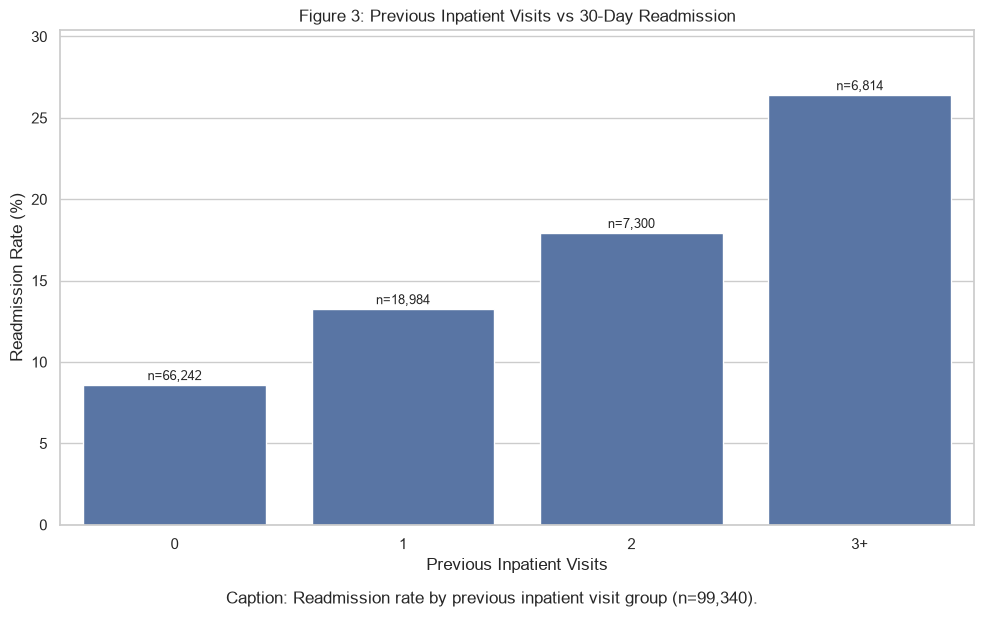

,prior_inpatient_group,total_encounters,readmitted,readmission_rate
0,0,66242,5690,8.589716
1,1,18984,2516,13.253266
2,2,7300,1309,17.931507
3,3+,6814,1799,26.401526


In [4]:
# Figure 3: Previous inpatient visits vs readmission

df["prior_inpatient_group"] = pd.cut(
    df["number_inpatient"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)

inpatient_analysis = (
    df.groupby("prior_inpatient_group", observed=False)
      .agg(
          total_encounters=("target", "size"),
          readmitted=("target", "sum"),
          readmission_rate=("target", "mean")
      )
      .reset_index()
)
inpatient_analysis["readmission_rate"] *= 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=inpatient_analysis,
    x="prior_inpatient_group",
    y="readmission_rate",
    order=["0", "1", "2", "3+"],
    ax=ax
)

ax.set_title("Figure 3: Previous Inpatient Visits vs 30-Day Readmission")
ax.set_xlabel("Previous Inpatient Visits")
ax.set_ylabel("Readmission Rate (%)")

for i, row in inpatient_analysis.iterrows():
    ax.text(
        i, row["readmission_rate"] + 0.3,
        f'n={row["total_encounters"]:,}',
        ha="center", fontsize=9
    )

ax.set_ylim(0, inpatient_analysis["readmission_rate"].max() + 4)
fig.text(0.5, -0.02, f"Caption: Readmission rate by previous inpatient visit group (n={len(df):,}).", ha="center")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig03_inpatient_readmission.png", dpi=300, bbox_inches="tight")
plt.show()

display(inpatient_analysis)


## 8. Figure 4 — Discharge Disposition vs Readmission

`discharge_disposition_id` is retained in v2 as an encoded category. The descriptive `discharge_disposition_id_desc` column from v1 is not part of the 20-column v2 schema.

This figure therefore uses the numeric disposition codes. Categories with fewer than 100 encounters are excluded from the plot to reduce unstable comparisons; the complete grouped table is also displayed.


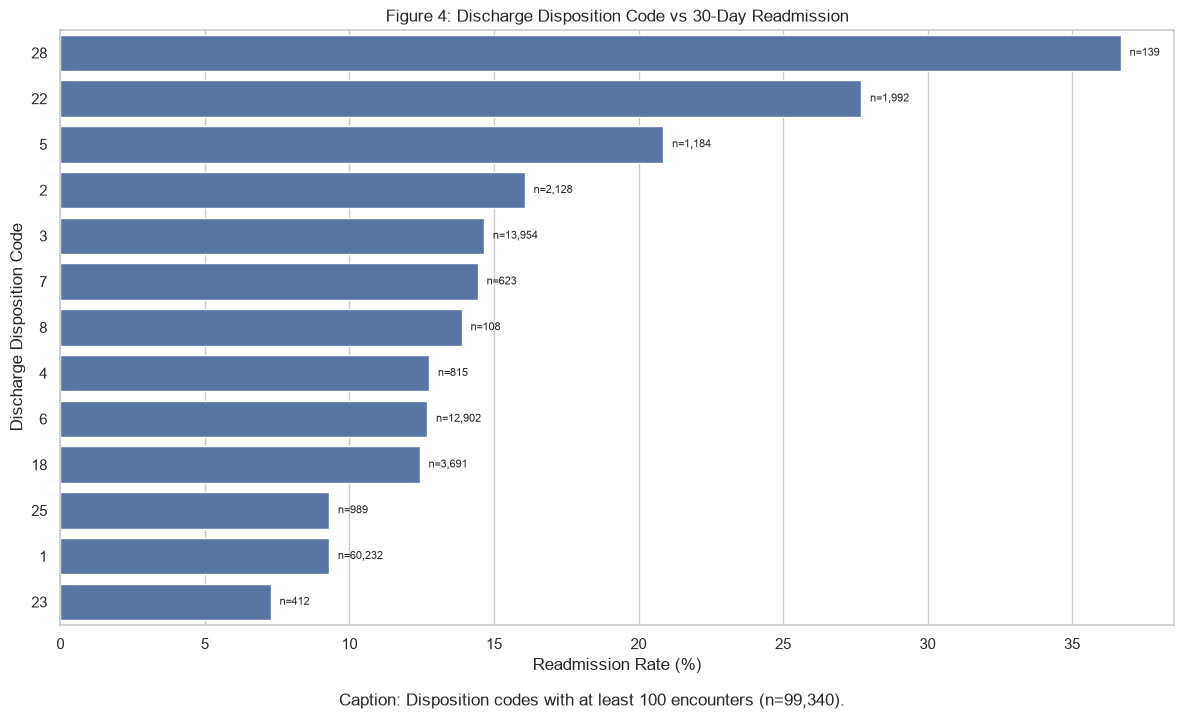

,discharge_disposition_id,total_encounters,readmitted,readmission_rate
0,1,60232,5602,9.300704
1,2,2128,342,16.071429
2,3,13954,2046,14.662462
3,4,815,104,12.760736
4,5,1184,247,20.861486
5,6,12902,1638,12.695706
6,7,623,90,14.446228
7,8,108,15,13.888889
8,9,21,9,42.857143
9,10,6,0,0.000000


In [5]:
# Figure 4: Discharge disposition vs readmission

discharge_analysis = (
    df.groupby("discharge_disposition_id", observed=True)
      .agg(
          total_encounters=("target", "size"),
          readmitted=("target", "sum"),
          readmission_rate=("target", "mean")
      )
      .reset_index()
)
discharge_analysis["readmission_rate"] *= 100

plot_data = (
    discharge_analysis[discharge_analysis["total_encounters"] >= 100]
    .sort_values("readmission_rate", ascending=False)
    .copy()
)
plot_data["disposition_code"] = plot_data["discharge_disposition_id"].astype(str)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=plot_data, x="readmission_rate", y="disposition_code", ax=ax)

ax.set_title("Figure 4: Discharge Disposition Code vs 30-Day Readmission")
ax.set_xlabel("Readmission Rate (%)")
ax.set_ylabel("Discharge Disposition Code")

for i, row in enumerate(plot_data.itertuples()):
    ax.text(row.readmission_rate + 0.3, i, f"n={row.total_encounters:,}", va="center", fontsize=8)

fig.text(0.5, -0.02, f"Caption: Disposition codes with at least 100 encounters (n={len(df):,}).", ha="center")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig04_discharge_readmission.png", dpi=300, bbox_inches="tight")
plt.show()

display(discharge_analysis)


## 9. Figure 5 — Distributions of Hospital Stay, Medications and Laboratory Procedures

This figure examines three numeric v2 attributes:

- `time_in_hospital`: length of the hospital stay in days.
- `num_medications`: number of medications recorded for the encounter.
- `num_lab_procedures`: number of laboratory procedures recorded for the encounter.

The v1 field `num_procedures` is not part of the v2 model schema, so it is not used here.


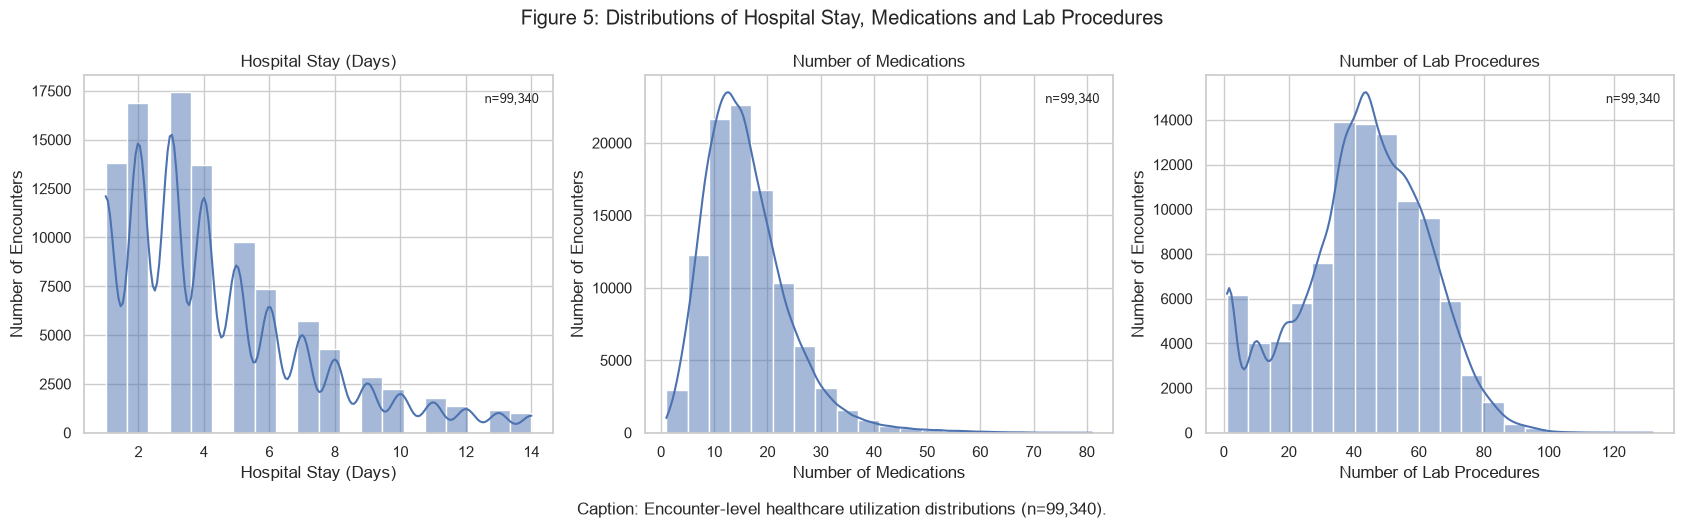

In [6]:
# Figure 5: Distributions of available v2 utilization variables

features = [
    ("time_in_hospital", "Hospital Stay (Days)"),
    ("num_medications", "Number of Medications"),
    ("num_lab_procedures", "Number of Lab Procedures")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (column, label) in zip(axes, features):
    sns.histplot(data=df, x=column, bins=20, kde=True, ax=ax)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of Encounters")
    ax.text(
        0.97, 0.95, f"n={df[column].count():,}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9
    )

fig.suptitle("Figure 5: Distributions of Hospital Stay, Medications and Lab Procedures")
fig.text(0.5, -0.03, f"Caption: Encounter-level healthcare utilization distributions (n={len(df):,}).", ha="center")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig05_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Figure 6 — Missing-Value Analysis of the Raw Dataset

Figure 6 intentionally uses the **original raw CSV**, not the processed v2 cohort. It therefore describes missingness before the cohort cleaning and feature-selection steps.

The raw file uses `?` as a missing-value marker. The chart displays the 20 columns with the highest missing percentages. This figure helps explain preprocessing decisions such as excluding `weight` and `payer_code`.

The zero-null result in the processed v2 dataset must not be confused with the missingness of the original raw dataset.


C:\Users\kavad\AppData\Local\Temp\ipykernel_5436\2514417599.py:3: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv(RAW_PATH, na_values=["?"])


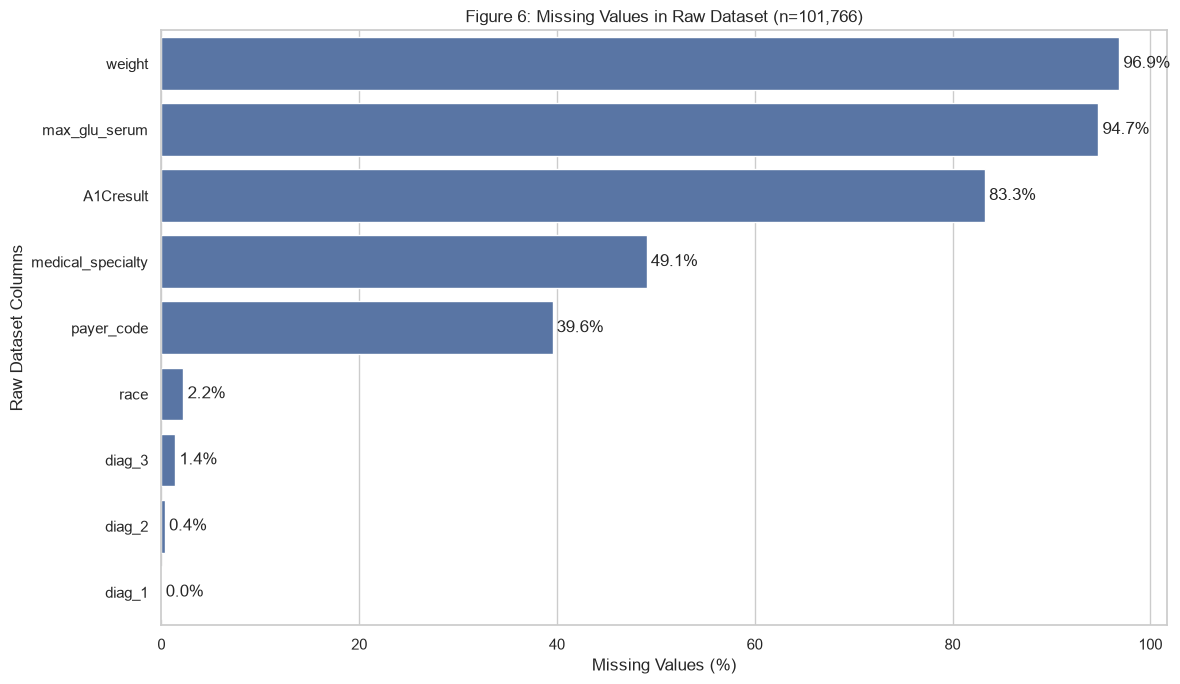

,missing_percentage
weight,96.858479
max_glu_serum,94.746772
A1Cresult,83.277322
medical_specialty,49.082208
payer_code,39.557416
race,2.233555
diag_3,1.398306
diag_2,0.351787
diag_1,0.020636


In [7]:
# Figure 6: Missing-value analysis — raw dataset only

raw_df = pd.read_csv(RAW_PATH, na_values=["?"])

missing_percent = (
    raw_df.isna().mean().mul(100)
    .sort_values(ascending=False)
)
missing_percent = missing_percent[missing_percent > 0].head(20)

fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index,
    ax=ax
)

ax.set_title(f"Figure 6: Missing Values in Raw Dataset (n={len(raw_df):,})")
ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Raw Dataset Columns")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig06_missing_values.png", dpi=300, bbox_inches="tight")
plt.show()

display(missing_percent.rename("missing_percentage").to_frame())


## 11. Figure 7 — HbA1c Result Category vs Readmission

The v2 schema retains `A1Cresult` but does not retain `max_glu_serum`. Figure 7 therefore focuses on HbA1c result categories only.

The source category `None` is retained as a category in the processed dataset; it is not a pandas null value. Readmission rates are calculated separately for each HbA1c category.


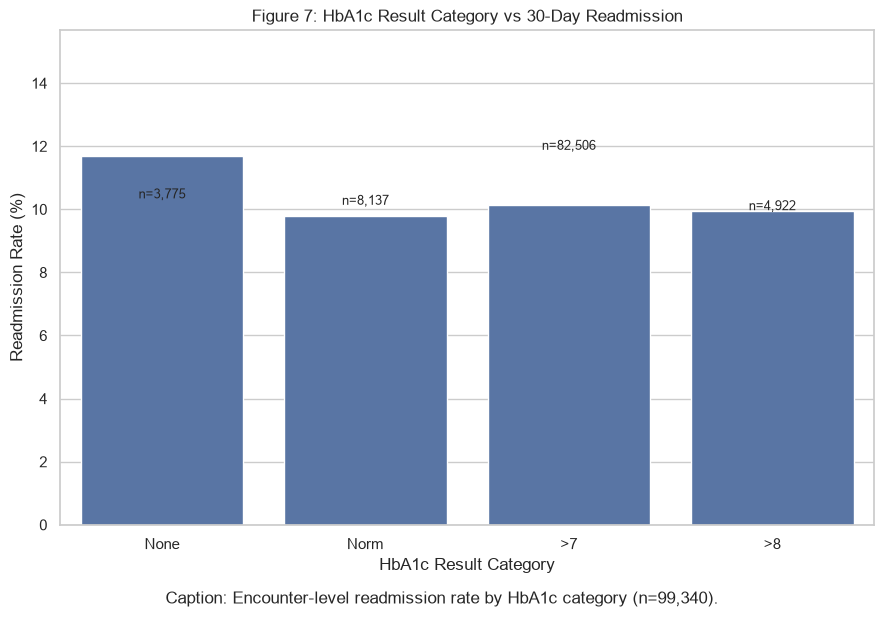

,A1Cresult,total_encounters,readmitted,readmission_rate
0,>7,3775,383,10.145695
1,>8,8137,809,9.942239
2,None,82506,9641,11.685211
3,Norm,4922,481,9.772450


In [8]:
# Figure 7: HbA1c result category vs readmission

a1c_analysis = (
    df.groupby("A1Cresult", observed=True)
      .agg(
          total_encounters=("target", "size"),
          readmitted=("target", "sum"),
          readmission_rate=("target", "mean")
      )
      .reset_index()
)
a1c_analysis["readmission_rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=a1c_analysis,
    x="A1Cresult",
    y="readmission_rate",
    order=["None", "Norm", ">7", ">8"],
    ax=ax
)

ax.set_title("Figure 7: HbA1c Result Category vs 30-Day Readmission")
ax.set_xlabel("HbA1c Result Category")
ax.set_ylabel("Readmission Rate (%)")

for i, row in a1c_analysis.iterrows():
    ax.text(
        i, row["readmission_rate"] + 0.2,
        f'n={row["total_encounters"]:,}',
        ha="center", fontsize=9
    )

ax.set_ylim(0, a1c_analysis["readmission_rate"].max() + 4)
fig.text(0.5, -0.02, f"Caption: Encounter-level readmission rate by HbA1c category (n={len(df):,}).", ha="center")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig07_lab_readmission.png", dpi=300, bbox_inches="tight")
plt.show()

display(a1c_analysis)


## 12. Figure 8 — Correlation Heatmap

The Pearson correlation coefficient describes the direction and strength of a linear relationship between two numeric variables:

- `+1`: perfect positive linear correlation.
- `-1`: perfect negative linear correlation.
- `0`: no linear correlation.

The heatmap uses numeric model attributes and the target. It explicitly excludes `encounter_id`, `patient_nbr`, and `n_stays_total`. It also excludes `is_first_encounter`, which is an auxiliary slicing field rather than a model attribute.

Correlation does not establish causation. The heatmap is an exploratory summary, not a feature-selection decision by itself.


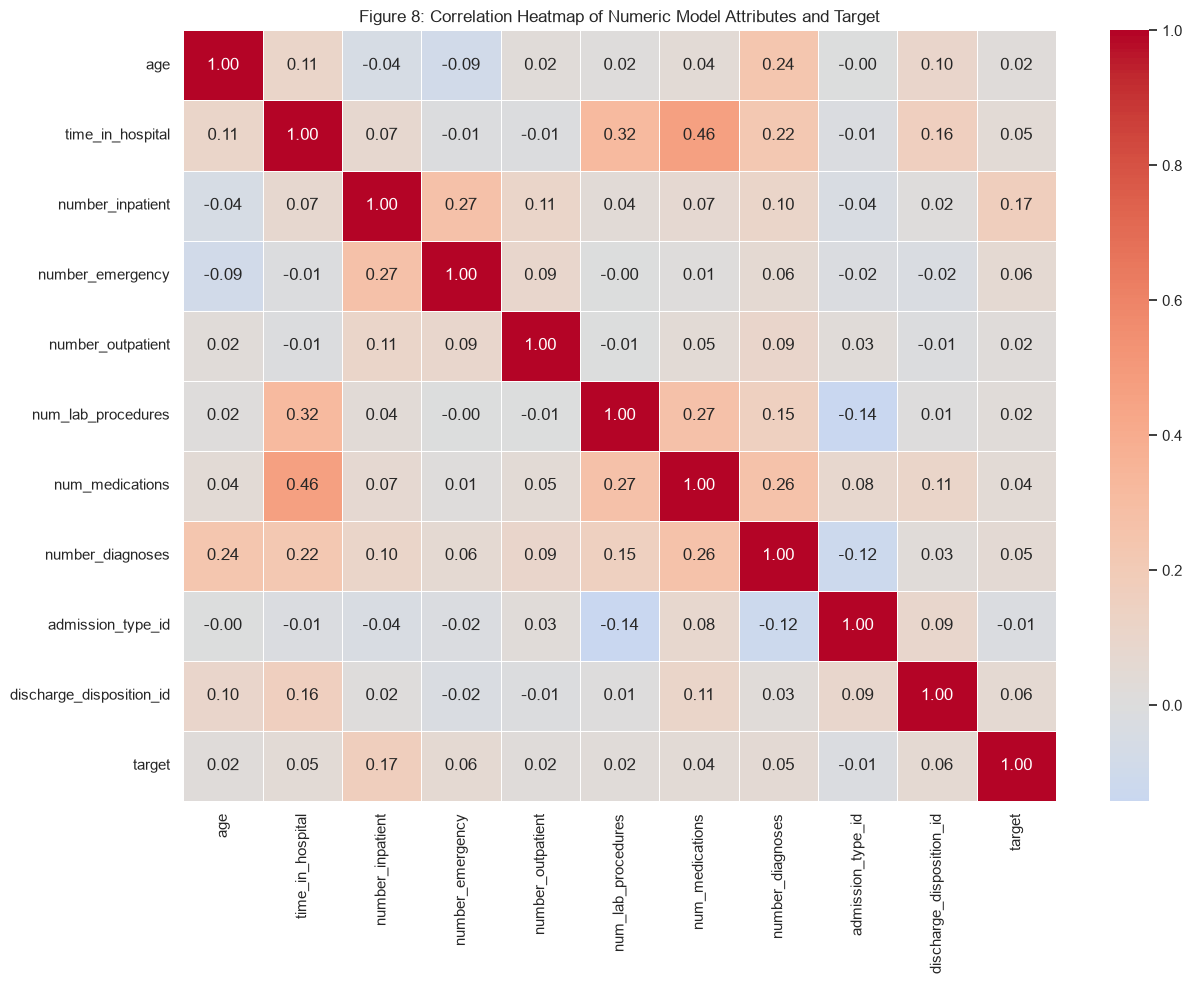

,age,time_in_hospital,number_inpatient,number_emergency,number_outpatient,num_lab_procedures,num_medications,number_diagnoses,admission_type_id,discharge_disposition_id,target
age,1.000000,0.107079,-0.044332,-0.087566,0.023675,0.016330,0.043158,0.241281,-0.004857,0.096306,0.022200
time_in_hospital,0.107079,1.000000,0.074247,-0.009575,-0.009218,0.319833,0.463759,0.220566,-0.012857,0.161122,0.046883
number_inpatient,-0.044332,0.074247,1.000000,0.267700,0.108012,0.039902,0.065268,0.104729,-0.037842,0.015750,0.168322
number_emergency,-0.087566,-0.009575,0.267700,1.000000,0.091667,-0.000983,0.014029,0.055991,-0.019414,-0.024347,0.060883
number_outpatient,0.023675,-0.009218,0.108012,0.091667,1.000000,-0.007614,0.046038,0.094825,0.026128,-0.009364,0.019166
num_lab_procedures,0.016330,0.319833,0.039902,-0.000983,-0.007614,1.000000,0.265164,0.149626,-0.141720,0.009743,0.024040
num_medications,0.043158,0.463759,0.065268,0.014029,0.046038,0.265164,1.000000,0.261642,0.081596,0.106209,0.041180
number_diagnoses,0.241281,0.220566,0.104729,0.055991,0.094825,0.149626,0.261642,1.000000,-0.115230,0.031263,0.053573
admission_type_id,-0.004857,-0.012857,-0.037842,-0.019414,0.026128,-0.141720,0.081596,-0.115230,1.000000,0.093672,-0.013221
discharge_disposition_id,0.096306,0.161122,0.015750,-0.024347,-0.009364,0.009743,0.106209,0.031263,0.093672,1.000000,0.063387


In [9]:
# Figure 8: Correlation heatmap — exclude identifiers and auxiliary leakage fields

excluded = [
    "encounter_id",
    "patient_nbr",
    "n_stays_total",
    "is_first_encounter"
]

numeric_df = df.select_dtypes(include="number").drop(
    columns=excluded,
    errors="ignore"
)

correlation_matrix = numeric_df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    ax=ax
)

ax.set_title("Figure 8: Correlation Heatmap of Numeric Model Attributes and Target")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig08_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

display(correlation_matrix)


## 13. Overall EDA Findings

The v2 exploratory analysis describes **99,340 encounters from 69,987 unique patients**. Since repeat encounters are retained, encounter-level counts and readmission rates should not be described as unique-patient counts or rates.

The analysis covers target imbalance, age groups, previous inpatient utilization, discharge disposition, healthcare utilization distributions, raw-data missingness, HbA1c categories, and numerical correlations.

Use the tables generated alongside each figure to report exact group rates and sample sizes. Avoid interpreting descriptive associations as causal effects.

### Important interpretation and data-use notes

1. The positive class contains 11,314 encounters (11.3892%); the negative class contains 88,026 encounters.
2. `number_inpatient` summarizes previous inpatient utilization and can be examined for association with the current encounter's readmission outcome.
3. Discharge disposition is represented by numeric codes in v2; descriptive labels from the v1 mapping columns are not included in this dataset.
4. Figure 5 uses `num_lab_procedures`, because `num_procedures` is not part of the v2 schema.
5. Figure 6 uses the raw dataset and must not be interpreted as the missingness profile of the processed v2 dataset.
6. Figure 7 analyzes `A1Cresult` only; `max_glu_serum` is not available in v2.
7. Figure 8 excludes identifiers and auxiliary encounter-history fields, including `n_stays_total`.

## 14. Conclusion

The v2 cohort preserves all eligible encounters and adds patient-level encounter-history fields while maintaining a clear distinction between model attributes and auxiliary columns.

These figures provide an exploratory foundation for downstream analysis. Further statistical testing and model evaluation are required to assess predictive performance and determine which features contribute useful information.
